# 01 Data description and exploratory analysis

Project: lake ice break-up in Finland, analysed with hierarchical Bayesian models.

Research questions:
- RQ1: How does a lake's location (latitude, longitude) affect the date its ice breaks up?
- RQ2: How has the break-up date changed over 1900-2026, and has the change sped up since about 1980?

Hypotheses:
- H1: Ice breaks up later further north. Longitude has at most a small effect.
- H2: Break-up dates were fairly stable early in the record and have moved earlier since roughly 1980.
- H3: The trend differs between lakes (the between-lake SD of the trend is above zero), and this may depend on latitude.

The data come from the SYKE Hydrology API (JaatJaanlahto, ice observations). We use code 28, the break-up of the ice cover as the observer sees it. Lake covariates come from the SYKE lake register. We cleaned the data earlier (see icebreak_variables.txt). Here we only pick the subset we model and make the figures for the Introduction and Data sections of the report.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import icebreak_common as ic

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
REGION_COLORS = {"south": "#2a6fbb", "central": "#3a9e6f", "north": "#c4572a"}

raw = pd.read_csv(ic.DATA_FILE)
places = pd.read_csv(ic.PLACES_FILE)
d_all = ic.load_breakup(recent_only=False)   # all 105 lake sites
d = ic.load_breakup(recent_only=True)        # main analysis: 64 sites reaching 2015+

print(f"Raw rows (site x season): {len(raw):,}   sites: {raw.Paikka_Id.nunique()}")
print(f"All sites with a break-up date: {len(d_all):,} rows, {d_all.site.nunique()} sites")
print(f"Main subset (reaches_recent):  {len(d):,} rows, {d.site.nunique()} sites, "
      f"seasons {d.season.min()}-{d.season.max()} ({d.season.nunique()} seasons)")
print(d.groupby("region").agg(sites=("site", "nunique"), rows=("site", "size"),
                              lat_min=("lat", "min"), lat_max=("lat", "max")).round(2))

Raw rows (site x season): 9,346   sites: 105
All sites with a break-up date: 9,021 rows, 105 sites
Main subset (reaches_recent):  6,093 rows, 64 sites, seasons 1900-2026 (127 seasons)
         sites  rows  lat_min  lat_max
region                                
central     27  2733    62.62    64.88
north       12   830    65.10    69.76
south       25  2530    60.42    62.26


## Summary of the outcome

In [2]:
summary = d[ic.RESPONSE].describe().round(1)
print(summary)
print("\nEarliest break-ups:")
print(d.nsmallest(5, ic.RESPONSE)[["Nimi", "season", "breakup_date", "lat"]].to_string(index=False))
print("\nLatest break-ups:")
print(d.nlargest(5, ic.RESPONSE)[["Nimi", "season", "breakup_date", "lat"]].to_string(index=False))

count    6093.0
mean      131.3
std        13.2
min        73.0
25%       123.0
50%       130.0
75%       138.0
max       181.0
Name: breakup_doy, dtype: float64

Earliest break-ups:
                  Nimi  season breakup_date       lat
     Kuivajärvi, Saari    2020   2020-03-13 60.781944
    Saimaa, Lauritsala    2020   2020-03-19 61.082778
    Pyhäjärvi, Kauttua    2020   2020-03-20 61.101389
Sääksjärvi, Sääkskoski    2020   2020-03-20 61.393611
      Vesijärvi, Lahti    2020   2020-03-24 60.994167

Latest break-ups:
             Nimi  season breakup_date       lat
      Kilpisjärvi    1958   1958-06-30 69.049167
      Kilpisjärvi    1998   1998-06-30 69.049167
Inari, selkävedet    1996   1996-06-29 68.956944
      Kilpisjärvi    1955   1955-06-29 69.049167
Inari, selkävedet    1932   1932-06-28 68.956944


## Figure 1: where the sites are
Mean break-up day at each site in the main subset. Lakes further north break up later (H1).

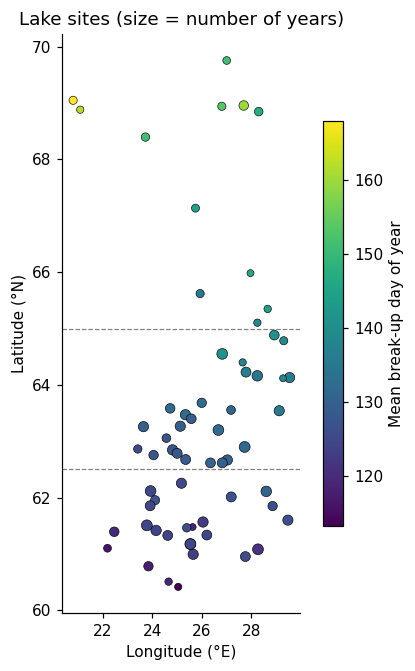

In [3]:
site = (d.groupby("site")
          .agg(lat=("lat", "first"), lon=("lon", "first"), name=("Nimi", "first"),
               region=("region", "first"), n=(ic.RESPONSE, "size"),
               mean_doy=(ic.RESPONSE, "mean"), sd_doy=(ic.RESPONSE, "std"),
               altitude=("lake_altitude_m", "first"), log_area=("log_lake_area", "first"))
          .reset_index())

fig, ax = plt.subplots(figsize=(4.6, 6.2))
sc = ax.scatter(site.lon, site.lat, c=site.mean_doy, s=site.n / 2.5, cmap="viridis",
                edgecolor="k", linewidth=0.4)
for cut in ic.REGION_CUTS[1:-1]:
    ax.axhline(cut, color="grey", lw=0.8, ls="--")
cb = fig.colorbar(sc, ax=ax, shrink=0.7)
cb.set_label("Mean break-up day of year")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Lake sites (size = number of years)")
ax.set_aspect(1 / np.cos(np.deg2rad(64)))
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig1_site_map.png", bbox_inches="tight")
plt.show()

## Figure 2: break-up day against latitude and longitude (site means)

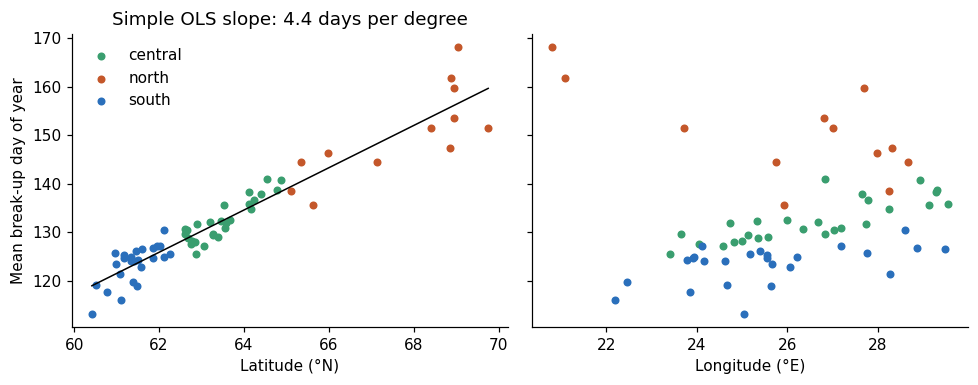

Correlations between site-level covariates:
           lat   lon  altitude  log_area
lat       1.00  0.09      0.65     -0.18
lon       0.09  1.00     -0.21      0.29
altitude  0.65 -0.21      1.00     -0.31
log_area -0.18  0.29     -0.31      1.00


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for reg, g in site.groupby("region"):
    axes[0].scatter(g.lat, g.mean_doy, s=18, color=REGION_COLORS[reg], label=reg)
    axes[1].scatter(g.lon, g.mean_doy, s=18, color=REGION_COLORS[reg], label=reg)
b_lat = np.polyfit(site.lat, site.mean_doy, 1)
xs = np.linspace(site.lat.min(), site.lat.max(), 10)
axes[0].plot(xs, np.polyval(b_lat, xs), color="k", lw=1)
axes[0].set_xlabel("Latitude (°N)")
axes[1].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Mean break-up day of year")
axes[0].legend(frameon=False)
axes[0].set_title(f"Simple OLS slope: {b_lat[0]:.1f} days per degree")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig2_lat_lon.png", bbox_inches="tight")
plt.show()

print("Correlations between site-level covariates:")
print(site[["lat", "lon", "altitude", "log_area"]].corr().round(2))

High lakes are all in Lapland, so latitude and altitude are correlated. We use latitude as the main location covariate and add longitude to test the second half of H1.

## Figure 3: break-up over time by region (H2)
Thin lines are the yearly mean over the sites in each region, thick lines an 11-year centred moving average.

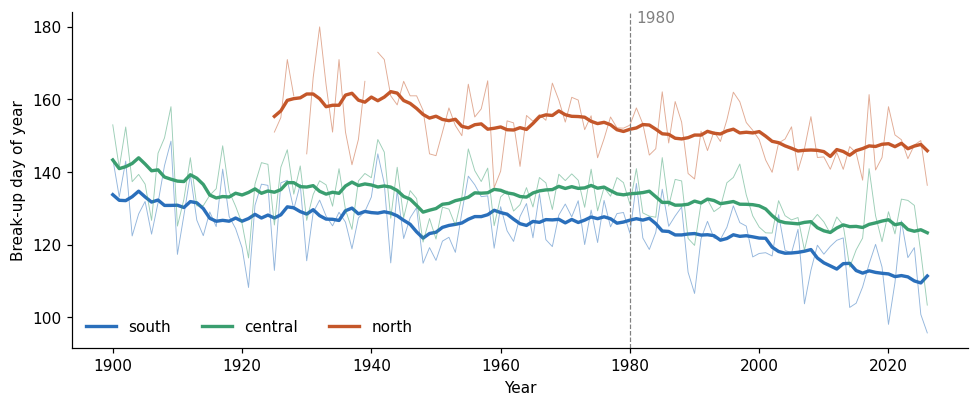

In [5]:
yr = d.groupby(["region", "season"])[ic.RESPONSE].mean().reset_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
for reg in ic.REGION_LABELS:
    g = yr[yr.region == reg].set_index("season")[ic.RESPONSE]
    g = g.reindex(range(d.season.min(), d.season.max() + 1))
    ax.plot(g.index, g.values, color=REGION_COLORS[reg], lw=0.6, alpha=0.5)
    ax.plot(g.index, g.rolling(11, center=True, min_periods=6).mean(), color=REGION_COLORS[reg],
            lw=2.2, label=reg)
ax.axvline(ic.BREAK_YEAR, color="grey", ls="--", lw=0.8)
ax.text(ic.BREAK_YEAR + 1, ax.get_ylim()[1] - 3, "1980", color="grey")
ax.set_xlabel("Year")
ax.set_ylabel("Break-up day of year")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig3_timeseries_region.png", bbox_inches="tight")
plt.show()

In [6]:
period_tab = pd.DataFrame({
    "All 105 sites": [d_all[d_all.season.between(a, b)][ic.RESPONSE].mean()
                      for a, b in [(1900, 1930), (1960, 1990), (2010, 2026)]],
    "64 sites reaching 2015+": [d[d.season.between(a, b)][ic.RESPONSE].mean()
                                for a, b in [(1900, 1930), (1960, 1990), (2010, 2026)]],
}, index=["1900-1930", "1960-1990", "2010-2026"]).round(1)
period_tab

,All 105 sites,64 sites reaching 2015+
1900-1930,130.5,132.5
1960-1990,132.4,134.1
2010-2026,124.0,124.0


## Figure 4: number of sites reporting each year
Many stations closed around 1990-2000. The main analysis keeps only sites whose records reach 2015 or later and includes a crossed year effect, which together reduce the bias from the shrinking network.

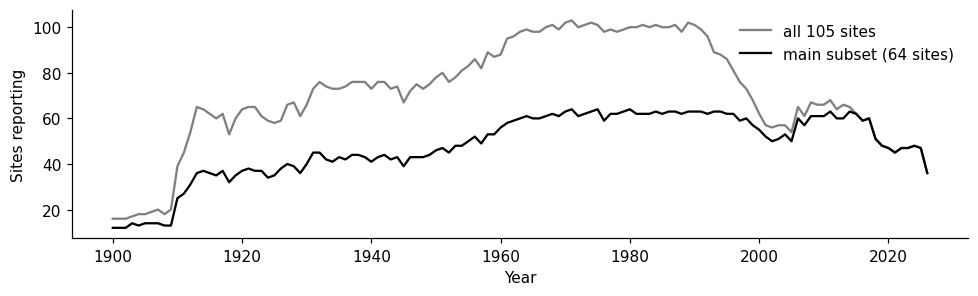

In [7]:
cnt_all = d_all.groupby("season").site.nunique()
cnt = d.groupby("season").site.nunique()
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(cnt_all.index, cnt_all.values, color="grey", label="all 105 sites")
ax.plot(cnt.index, cnt.values, color="k", label="main subset (64 sites)")
ax.set_xlabel("Year")
ax.set_ylabel("Sites reporting")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig4_sites_per_year.png", bbox_inches="tight")
plt.show()

## Figure 5: why crossed effects and a Student-t likelihood?
A quick non-Bayesian check: subtract additive site and year means and look at what is left.
- Much of the variation is shared by all lakes in a given year (a cold or warm spring), so observations from the same year are not independent. That calls for a crossed year effect.
- The residuals have heavy tails, so we use a Student-t observation model.
- The residuals spread more in the north, since a cold spring in Lapland is not always a cold spring in the south. Model M3 adds year effects for each region to handle this.

There is no shrinkage in this decomposition, so the region-year version overfits a bit (the north has only 12 sites). LOO-CV in notebook 03 decides whether M3 actually predicts better.

SD of site means: 11.4 days, SD of year effects: 8.3 days, residual SD: 4.2 days
Residual excess kurtosis: 5.4 (0 for a normal distribution)

Residual SD by region:
         site+year  site+year+region-year
region                                   
central        3.4                    3.0
north          6.5                    3.8
south          4.1                    3.1


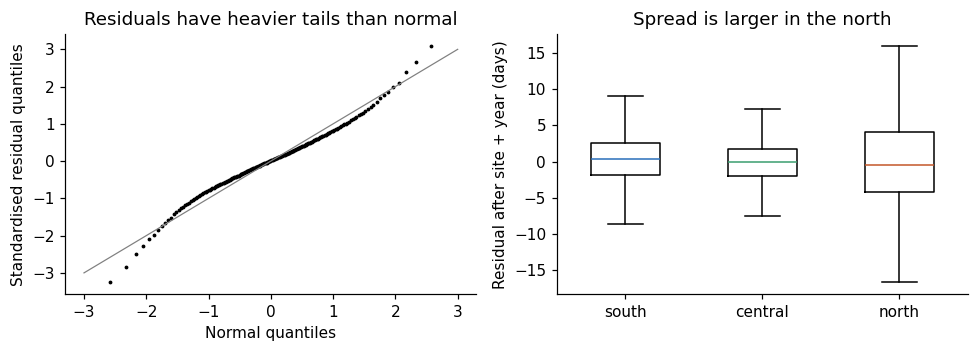

In [8]:
def additive_decomposition(df, groups, n_iter=60):
    y = df[ic.RESPONSE].to_numpy(dtype=float)
    eff = {g: pd.Series(0.0, index=df[g].unique()) for g in groups}
    for _ in range(n_iter):
        for g in groups:
            other = sum(eff[h].reindex(df[h]).to_numpy() for h in groups if h != g)
            eff[g] = pd.Series(y - other).groupby(df[g].to_numpy()).mean()
            if g != groups[0]:
                eff[g] -= eff[g].mean()
    fitted = sum(eff[g].reindex(df[g]).to_numpy() for g in groups)
    return y - fitted, eff

res1, eff1 = additive_decomposition(d, ["site", "season_f"])
res2, _ = additive_decomposition(d, ["site", "season_f", "season_region"])
print(f"SD of site means: {eff1['site'].std():.1f} days, SD of year effects: "
      f"{eff1['season_f'].std():.1f} days, residual SD: {res1.std():.1f} days")
from scipy import stats
print(f"Residual excess kurtosis: {stats.kurtosis(res1):.1f} (0 for a normal distribution)")
tmp = pd.DataFrame({"region": d.region, "site+year": res1, "site+year+region-year": res2})
print("\nResidual SD by region:")
print(tmp.groupby("region")[["site+year", "site+year+region-year"]].std().round(1))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
q = np.linspace(0.005, 0.995, 200)
axes[0].plot(stats.norm.ppf(q), np.quantile(res1 / res1.std(), q), ".", ms=3, color="k")
axes[0].plot([-3, 3], [-3, 3], color="grey", lw=0.8)
axes[0].set_xlabel("Normal quantiles")
axes[0].set_ylabel("Standardised residual quantiles")
axes[0].set_title("Residuals have heavier tails than normal")
for i, reg in enumerate(ic.REGION_LABELS):
    axes[1].boxplot(res1[d.region == reg], positions=[i], widths=0.5, showfliers=False,
                    medianprops={"color": REGION_COLORS[reg]})
axes[1].set_xticks(range(3), ic.REGION_LABELS)
axes[1].set_ylabel("Residual after site + year (days)")
axes[1].set_title("Spread is larger in the north")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig5_residual_structure.png", bbox_inches="tight")
plt.show()

## Secondary outcomes (not modelled in the main analysis)
Freeze-up is counted from 1 September, and ice duration runs from freeze-up to the next break-up. The 2026 freeze-up season is incomplete.

In [9]:
sec = d.agg({"freeze_day_from_sep1": ["count", "mean", "std"], "ice_duration": ["count", "mean", "std"]})
sec.round(1)

,freeze_day_from_sep1,ice_duration
count,5727.0,5727.0
mean,85.5,167.9
std,20.4,29.2


## Table for the report: data used in the main analysis

In [10]:
tab = pd.DataFrame({
    "Observation sites (lakes)": [d.site.nunique()],
    "Distinct lakes (Jarvi_Id)": [d.Jarvi_Id.nunique()],
    "Seasons": [f"{d.season.min()}-{d.season.max()}"],
    "Break-up observations": [len(d)],
    "Mean break-up (day of year)": [round(d[ic.RESPONSE].mean(), 1)],
    "SD (days)": [round(d[ic.RESPONSE].std(), 1)],
}).T.rename(columns={0: "value"})
tab

,value
Observation sites (lakes),64
Distinct lakes (Jarvi_Id),59
Seasons,1900-2026
Break-up observations,6093
Mean break-up (day of year),131.3
SD (days),13.2
